# Mechanics 1: Motion and Newton's laws

*Learning path: mechanics, part 1 of 7.* [Index](README.md) · Next: [Energy and momentum](02-energy-and-momentum.ipynb)

A good baseball hit leaves the bat at about 45 m/s, roughly 160 km/h. The textbook formula for a projectile says it
should land almost 200 m away. The longest home runs ever measured travel about 150 m, and a typical one about 120 m.
Where do the missing 80 m go? Into the air. This lesson sets up the language of mechanics (quantities with units,
vectors, Newton's second law), solves the projectile exactly, and then adds air drag, which has no formula but which
Galileo solves numerically in one line.

**Who this is for.** You know derivatives and integrals ([foundations 7](../foundations/07-calculus.ipynb)) and have
met differential equations ([differential equations 1](../differential-equations/01-first-order-equations.ipynb)).
No physics course is assumed.

**What you will be able to do afterwards:**

1. compute with physical quantities and units, convert between units, and use dimensions to check formulas;
2. describe motion with position, velocity and acceleration vectors;
3. state Newton's three laws and turn the second into differential equations;
4. solve projectile motion exactly, and find the angle of longest range;
5. add quadratic air drag, solve it numerically, and compute a terminal velocity.

Plan about an hour and a half.

## 1. Quantities and units

A physical quantity is a number **and** a unit. In Galileo you write them together, as on paper:

In [1]:
v = 45 m/s
convert(v, km/h)
eval(convert(v, mph), 4)

45 m/s

> `unit`: x with units: unit(3, "m/s") is 3 m/s.

162 km/h

> `convert`: Converts a quantity to other units of the same dimension: convert(100 km/h, m/s), convert(2 kg*3 m/s^2, N).

100.7 mph

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Units travel through the arithmetic. A speed times a time is a distance, a mass times an acceleration is a force, and
units of the same kind combine:

In [2]:
v*(3 s)
F = 0.145 kg * 9.81 m/s^2
convert(F, N)
1 km + 250 m

135 m

1.42245 kg*m/s^2

1.42245 N

> `convert`: Converts a quantity to other units of the same dimension: convert(100 km/h, m/s), convert(2 kg*3 m/s^2, N).

1.25 km

Adding a length to a time is an error in Galileo, as it is in physics: only quantities of the same **dimension** can be
added or compared. `dimension` names the dimension of any quantity, and this is a quick check of a formula. Is
$\sqrt{2h/g}$ a time?

In [3]:
dimension(const.g)
h = 10 m;
dimension(sqrt(2*h/const.g))
eval(convert(sqrt(2*h/const.g)), 3)

"length/time^2"

> `dimension`: The dimension of a quantity in words: dimension(3 m/s) is "length/time".

"time"

> `dimension`: The dimension of a quantity in words: dimension(3 m/s) is "length/time".

1.43 s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

It is: a stone dropped from 10 m lands after 1.43 s. `eval(q, n)` rounds a quantity to $n$ significant digits, which
is how the rest of the lesson shows results. `const.g` is standard gravity, 9.80665 m/s²; `const` holds other
physical constants as well (`const.c`, `const.G`, ...). `convert(q)` with no target gives SI base units, and
`value(q, unit)` gives the bare number, which is what plots need.

**Try this.** How long does light take to cross a proton (diameter about $1.7 \times 10^{-15}$ m)? Use `const.c` and
convert the answer to seconds.

## 2. Position, velocity, acceleration

In the plane a moving object has a **position vector** $\mathbf r(t) = (x(t), y(t))$. Its **velocity** is the derivative
$\mathbf v = d\mathbf r/dt$ and its **acceleration** is $\mathbf a = d\mathbf v/dt$. For a stone thrown with velocity
$(v_x, v_y)$ from the origin, gravity pulls straight down with acceleration $g$:

In [4]:
r = [vx*t, vy*t - g*t^2/2]
vel = diff(r, t)
acc = diff(vel, t)

[t*vx, t*vy-g*t^2/2]

[vx, vy-g*t]

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

[0, -g]

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

The velocity changes only in its vertical part, at the constant rate $-g$. The **speed** is the length of the velocity
vector, $|\mathbf v| = \sqrt{v_x^2 + v_y^2}$:

In [5]:
speed = sqrt(vel(1)^2 + vel(2)^2)
subs(subs(subs(speed, vx, 3), vy, 4), t, 0)

sqrt(vx^2+(vy-g*t)^2)

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

5

> `subs`: Replaces the variable x by a value.

**Try this.** At what time is the stone highest? (The vertical velocity is zero there.) Solve `vel(2) == 0` for $t$.

## 3. Newton's laws

Isaac Newton's *Principia* (1687) states three laws:

1. A body stays at rest or moves in a straight line at constant speed unless a force acts on it.
2. The force changes the motion: $\mathbf F = m\mathbf a$, or, with momentum $\mathbf p = m\mathbf v$,
   $\mathbf F = d\mathbf p/dt$.
3. Forces come in pairs: if A pushes B, B pushes A equally hard in the opposite direction.

The second law is the working tool. Given the forces, $m\,d^2\mathbf r/dt^2 = \mathbf F$ is a differential equation
for the motion. The unit of force is the newton, $1\ \text{N} = 1\ \text{kg m/s}^2$:

In [6]:
convert(1 N)
W = 70 kg * const.g;
eval(convert(W, N), 4)

1 kg*m/s^2

> `convert`: Converts a quantity to other units of the same dimension: convert(100 km/h, m/s), convert(2 kg*3 m/s^2, N).

686.5 N

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A person of 70 kg weighs about 686.5 N. (Weight is a force; the mass is what the scale divides by $g$.)

**Try this.** A car of 1200 kg brakes from 100 km/h to rest in 4 s. What is the average force on it, in newtons?

## 4. Projectiles without air

Without air the only force is gravity, $\mathbf F = (0, -mg)$, so $x'' = 0$ and $y'' = -g$. Galileo solves them:

In [7]:
dsolve(x'' == 0, x, t, 0, [0 vx])
dsolve(y'' == -g, y, t, 0, [0 vy])

t*vx

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

t*vy-g*t^2/2

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

That is the $\mathbf r(t)$ of section 2. The ball lands when $y = 0$ again, at $T = 2v_y/g$, and has then travelled
$R = v_xT = 2v_xv_y/g$. With $v_x = v_0\cos\theta$ and $v_y = v_0\sin\theta$ this is the **range formula**
$R = v_0^2\sin 2\theta/g$. For the baseball, launched at 45 m/s and 35 degrees:

In [8]:
v0 = 45 m/s; th = 35 deg;
vx0 = eval(v0*cos(th));
vy0 = eval(v0*sin(th));
T = 2*vy0/const.g;
R = vx0*T;
[eval(vx0, 3), eval(vy0, 3), eval(T, 3), eval(R, 3)]

[(36.9 m/s), (25.8 m/s), (5.26 s), (194.0 m)]

194 m, as promised in the introduction. The range is largest when $\sin 2\theta = 1$, at 45 degrees:

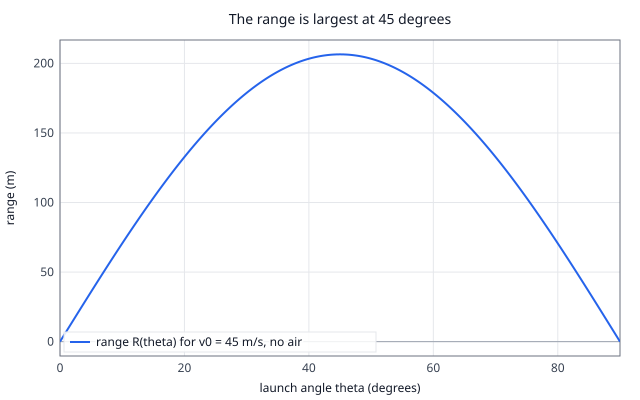

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = plot(45^2*sin(2*a*pi/180)/9.80665, a, 0, 90);
labels(title(legend(p, "range R(theta) for v0 = 45 m/s, no air"), "The range is largest at 45 degrees"), "launch angle theta (degrees)", "range (m)")

Here is the flight itself; press play to watch it (on paper, later moments are drawn faintly):

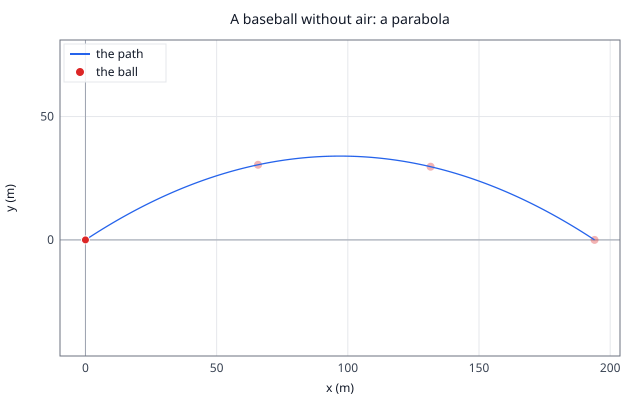

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
vxn = value(vx0); vyn = value(vy0); Tn = value(T);
p = animate(vxn*t, vyn*t - 9.80665*t^2/2, t, 0, Tn);
p = legend(p, "the path", "the ball");
labels(title(p, "A baseball without air: a parabola"), "x (m)", "y (m)")

**Try this.** Show that angles $45° + \alpha$ and $45° - \alpha$ give the same range. (Use $\sin(90° \pm 2\alpha)$.)

## 5. Air drag

A ball moving through air pushes air out of its way, and the air pushes back. At these speeds the drag force points
against the velocity and grows with the square of the speed,

$$\mathbf F_{\text{drag}} = -c\,|\mathbf v|\,\mathbf v, \qquad c = \tfrac12\rho C_d A,$$

with $\rho$ the density of air, $A$ the cross section of the ball and $C_d$ a **drag coefficient** measured in wind
tunnels (about 0.35 for a baseball). With units, the constant $k = c/m$ comes out as an inverse length:

In [11]:
m = 0.145 kg; d = 7.4 cm; Cd = 0.35; rho = 1.2 kg/m^3;
A = eval(pi*(d/2)^2);
c = rho*Cd*A/2;
k = c/m;
eval(c, 3)
eval(k, 3)

0.000903 kg/m

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.00623 m^-1

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Newton's second law with gravity and drag, written as four first-order equations for $x$, $y$ and the velocity
$(u, w)$, is

$$x' = u, \quad y' = w, \quad u' = -k\sqrt{u^2 + w^2}\,u, \quad w' = -g - k\sqrt{u^2 + w^2}\,w.$$

The square root couples the two directions, and there is no formula for the solution. `odeplot` solves it numerically
(Runge–Kutta) and draws the path. Compare with no air:

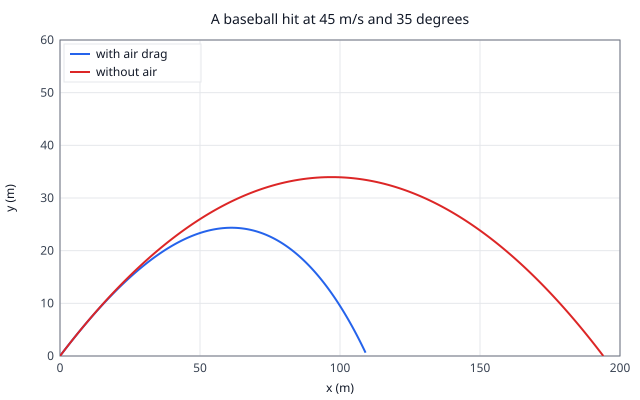

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [12]:
kk = value(k); gg = value(const.g);
start = [0 0 vxn vyn];
drag = [u, w, -kk*sqrt(u^2 + w^2)*u, -gg - kk*sqrt(u^2 + w^2)*w];
p = odeplot(drag, [x y u w], t, start, 0, 4.4, [x y]);
p = show(p, odeplot([u, w, 0, -gg], [x y u w], t, start, 0, Tn, [x y]));
p = window(p, 0, 200, 0, 60);
p = legend(p, "with air drag", "without air");
labels(title(p, "A baseball hit at 45 m/s and 35 degrees"), "x (m)", "y (m)")

With air the ball lands near 110 m, and the path is no longer symmetric: it comes down more steeply than it went up,
because drag has taken away horizontal speed. To find the landing point, tabulate the solution with
`odedata` (one row $[t\ x\ y\ u\ w]$ every 0.01 s), find the first row below the ground, and interpolate between it and
the row before:

In [13]:
D = odedata(drag, [x y u w], t, start, 0, 4.6, 460);
j = 2;
while D(j, 3) > 0
  j = j + 1;
end
tland = D(j - 1, 1) + 0.01*D(j - 1, 3)/(D(j - 1, 3) - D(j, 3));
xland = D(j - 1, 2) + (D(j, 2) - D(j - 1, 2))*D(j - 1, 3)/(D(j - 1, 3) - D(j, 3));
[round(tland, 2), round(xland, 1)]

[4.43, 109.7]

The ball lands after 4.43 s, about 110 m away: 84 m short of the vacuum answer. That is most of the gap from the
introduction. (Real baseballs also spin, which adds lift; that is why the longest home runs reach 150 m.)

**Terminal velocity.** Falling straight down, drag grows until it balances gravity: $mg = c v_t^2$, so
$v_t = \sqrt{g/k}$.

In [14]:
vt = sqrt(const.g/k);
eval(vt, 3)
eval(convert(vt, km/h), 4)

39.7 m/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

142.8 km/h

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A baseball dropped from a great height never falls faster than about 40 m/s. Here is the drop from rest, compared with
free fall, using the vertical equation alone:

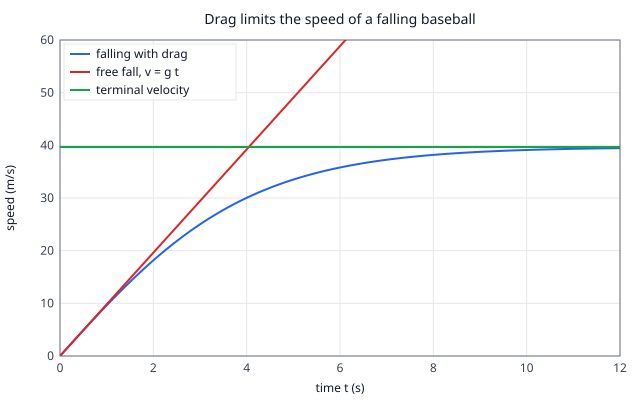

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [15]:
p = odeplot([-gg + kk*w^2], [w], t, [0], 0, 12, [t -w]);
p = show(p, plot(gg*t, t, 0, 12));
p = show(p, plot(value(vt), t, 0, 12));
p = window(p, 0, 12, 0, 60);
p = legend(p, "falling with drag", "free fall, v = g t", "terminal velocity");
labels(title(p, "Drag limits the speed of a falling baseball"), "time t (s)", "speed (m/s)")

(The drag on a falling ball points up, so $w' = -g + kw^2$ while $w < 0$.)

**Try this.** A ping-pong ball has $m = 2.7$ g, diameter 4 cm and $C_d \approx 0.5$. Compute its terminal velocity. Why
is it so much smaller than the baseball's?

## Summary

* A physical quantity is a number with a unit: `3 m/s`. Units carry through arithmetic, `convert` changes them, and
  only quantities of the same dimension can be added. Checking dimensions catches wrong formulas.
* Velocity and acceleration are the first and second derivatives of the position vector.
* Newton's second law $\mathbf F = m\mathbf a$ turns forces into differential equations.
* Without air a projectile follows a parabola, with range $R = v_0^2\sin 2\theta/g$, largest at 45 degrees.
* Quadratic drag $-c|\mathbf v|\mathbf v$ couples the two directions; the equations are solved numerically, and the
  terminal velocity is $\sqrt{mg/c}$.

Next: [energy and momentum](02-energy-and-momentum.ipynb), the conserved quantities that often make solving the
equations unnecessary.

## Exercises

1. **Units.** A marathon is 42.195 km. A runner finishes in 2 h 5 min. What is the average speed in m/s and in mph?
2. **Dimensions.** The period of a pendulum can depend only on its length $\ell$, the mass $m$ and $g$. Which
   combination of them is a time? Check with `dimension`.
3. **Dropped and thrown.** A ball is thrown horizontally at 12 m/s from a 20 m cliff. Where does it land? Solve without
   air.
4. **Highest point.** Show that a projectile without air reaches height $H = v_0^2\sin^2\theta/2g$. How high does the
   baseball of section 4 go?
5. **Optimal angle with drag.** Use `odeplot` to find, roughly, the launch angle that gives the baseball its longest
   range with drag. Is it more or less than 45 degrees?
6. **Skydiver.** A skydiver of 80 kg has $c \approx 0.25$ kg/m. Compute the terminal velocity in km/h.

## Hints and answers

* **Section 1, Try this.** `convert(1.7e-15 m/const.c, s)` is about $5.7 \times 10^{-24}$ s.
* **Section 2, Try this.** `solve(vel(2) == 0, t)` gives $t = v_y/g$.
* **Section 3, Try this.** $\Delta v = 27.8$ m/s in 4 s is $6.94$ m/s², so $F \approx 8300$ N:
  `convert(1200 kg*(100 km/h)/(4 s), N)`.
* **Section 4, Try this.** $\sin(90° + 2\alpha) = \sin(90° - 2\alpha) = \cos 2\alpha$.
* **Section 5, Try this.** $k = \tfrac12\rho C_dA/m \approx 0.14$ per metre, so $v_t \approx 8.4$ m/s. The ball is
  light for its size: the cross section per unit mass is about 25 times the baseball's.
* **Exercise 1.** `convert(42.195 km/(125 min), m/s)` is 5.63 m/s, about 12.6 mph.
* **Exercise 2.** $\sqrt{\ell/g}$; the mass cannot appear, since nothing else has a unit of mass to cancel it. The full
  answer is $2\pi\sqrt{\ell/g}$ ([oscillations](../waves/01-harmonic-oscillator.ipynb)).
* **Exercise 3.** It falls for $\sqrt{2 \cdot 20/g} = 2.02$ s, landing 24.2 m out.
* **Exercise 4.** At the top $w = 0$, at $t = v_y/g$, which gives $H = v_y^2/2g$; for the baseball 34 m.
* **Exercise 5.** Around 38 to 40 degrees: with drag a flatter path loses less speed.
* **Exercise 6.** $\sqrt{mg/c} = \sqrt{80 \cdot 9.81/0.25} \approx 56$ m/s, about 200 km/h.

## Sources

1. I. Newton, *Philosophiæ Naturalis Principia Mathematica*, London (1687); English translation by I. B. Cohen and
   A. Whitman, University of California Press (1999).
2. G. Galilei, *Discorsi e dimostrazioni matematiche intorno a due nuove scienze*, Leiden (1638), fourth day (the
   parabola of projectiles).
3. R. K. Adair, *The Physics of Baseball*, 3rd ed., Harper Collins (2002), chapter 3 (drag on a baseball).
4. J. R. Taylor, *Classical Mechanics*, University Science Books (2005), chapters 1 and 2.
5. BIPM, *The International System of Units (SI)*, 9th ed. (2019); E. Tiesinga et al., CODATA recommended values of the
   fundamental physical constants: 2022.